# Camada Gold e Análise de Negócio

**Projeto Avaliativo Módulo 1** | Filippe Borba | Analise_de_Dados_T6 (SENAI)

Este notebook constrói a camada Gold a partir da Silver e responde as 7 perguntas de negócio definidas no enunciado.

**Pré-requisito:** executar `0_criar_banco.sql`, `1_extrair.py` e `2_transformar.py` antes.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from banco import conectar, executar
from matplotlib.ticker import FuncFormatter


warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

conexao = conectar()
print("Conectado ao banco transparencia")

Conectado ao banco transparencia


## 1. Camada Gold agregada

Cria as VIEWs agregadas. O mesmo DDL está versionado em `sql/gold_agregada.sql`.

In [2]:
DDL_VIEWS = """
CREATE OR REPLACE VIEW gold_gastos_por_orgao AS
SELECT
    nome_orgao_superior,
    COUNT(*)                        AS qtd_viagens,
    SUM(valor_total)                AS valor_total_gasto,
    ROUND(AVG(valor_total), 2)      AS valor_medio_viagem,
    SUM(valor_diarias)              AS total_diarias,
    SUM(valor_passagens)            AS total_passagens,
    SUM(valor_devolucao)            AS total_devolucao,
    SUM(valor_outros_gastos)        AS total_outros_gastos,
    ROUND(AVG(duracao_dias), 1)     AS duracao_media_dias
FROM silver_viagem
GROUP BY nome_orgao_superior;

CREATE OR REPLACE VIEW gold_pagamentos_por_orgao AS
SELECT
    nome_orgao_pagador,
    COUNT(*)                        AS qtd_pagamentos,
    SUM(valor)                      AS valor_total_pago,
    ROUND(AVG(valor), 2)            AS valor_medio_pagamento,
    COUNT(DISTINCT tipo_pagamento)  AS tipos_distintos
FROM silver_pagamento
GROUP BY nome_orgao_pagador;

CREATE OR REPLACE VIEW gold_gastos_por_destino AS
SELECT
    TRIM(SPLIT_PART(destinos, ',', 1))  AS destino_principal,
    COUNT(*)                            AS qtd_viagens,
    SUM(valor_total)                    AS valor_total_gasto,
    ROUND(AVG(valor_total), 2)          AS valor_medio_viagem
FROM silver_viagem
WHERE destinos IS NOT NULL
GROUP BY TRIM(SPLIT_PART(destinos, ',', 1));
"""

executar(conexao, DDL_VIEWS)
print("VIEWs criadas: gold_gastos_por_orgao, gold_pagamentos_por_orgao, gold_gastos_por_destino")

VIEWs criadas: gold_gastos_por_orgao, gold_pagamentos_por_orgao, gold_gastos_por_destino


In [3]:
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."))
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


def fmt_moeda(valor, pos=None):
    """Formata eixo em reais: 1200000000 -> R$ 1,2 bi"""
    if abs(valor) >= 1_000_000_000:
        return f"R$ {valor / 1_000_000_000:.1f} bi".replace(".", ",")
    if abs(valor) >= 1_000_000:
        return f"R$ {valor / 1_000_000:.1f} mi".replace(".", ",")
    if abs(valor) >= 1_000:
        return f"R$ {valor / 1_000:.0f} mil"
    return f"R$ {valor:.0f}"


def fmt_moeda_completo(valor, pos=None):
    """Formata eixo em reais com separador de milhar: 1200000000 -> R$ 1.200.000.000"""
    return f"R$ {valor:,.0f}".replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_percentual(valor, pos=None):
    """Formata eixo em percentual: 45.3 -> 45,3%"""
    return f"{valor:.1f}%".replace(".", ",")


def fmt_inteiro(valor, pos=None):
    """Formata eixo com separador de milhar: 763349 -> 763.349"""
    return f"{valor:,.0f}".replace(",", "X").replace(".", ",").replace("X", ".")


print("Formatadores de eixo definidos")

Formatadores de eixo definidos


In [4]:
def consultar_df(sql: str) -> pd.DataFrame:
    """
    Executa um SELECT e devolve DataFrame com colunas numericas convertidas.

    Args:
        sql: comando SELECT a executar.

    Returns:
        DataFrame com os resultados da consulta.
    """
    df = pd.read_sql(sql, conexao)
    for coluna in df.columns:
        if df[coluna].dtype == object:
            try:
                df[coluna] = pd.to_numeric(df[coluna])
            except (ValueError, TypeError):
                pass
    return df


def formatar_moeda(valor: float) -> str:
    """Formata um numero no padrao monetario brasileiro."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


df_orgao = consultar_df("SELECT * FROM gold_gastos_por_orgao")
print(f"gold_gastos_por_orgao: {len(df_orgao)} orgaos")
df_orgao.head(10)

gold_gastos_por_orgao: 35 orgaos


,nome_orgao_superior,qtd_viagens,valor_total_gasto,valor_medio_viagem,total_diarias,total_passagens,total_devolucao,total_outros_gastos,duracao_media_dias
0,Advocacia-Geral da União,1334,"4.194.876,48","3.144,59","1.808.301,59","2.337.440,24","14.286,53","34.848,12","2,90"
1,Banco Central do Brasil - Orçamento Fiscal e S...,385,"2.615.023,79","6.792,27","1.180.152,91","1.391.345,25","0,00","43.525,63","2,90"
2,Controladoria-Geral da União,845,"1.987.181,87","2.351,69","1.264.488,56","676.159,08","37.180,12","9.354,11","3,10"
3,"Ministério da Ciência, Tecnologia e Inovação",3109,"13.623.616,94","4.381,99","5.125.419,24","8.361.689,38","81.259,70","55.248,62","2,60"
4,Ministério da Cultura,1929,"9.419.997,74","4.883,36","3.119.031,86","6.240.151,98","22.596,30","38.217,60","3,30"
5,Ministério da Defesa,61912,"157.059.698,59","2.536,82","93.008.554,68","62.936.931,92","494.697,05","619.514,94","5,20"
6,Ministério da Educação,65295,"112.519.456,96","1.723,25","59.882.705,76","51.047.964,39","614.053,81","974.733,00","2,70"
7,Ministério da Fazenda,11854,"32.857.642,63","2.771,86","19.105.395,38","13.098.965,55","191.625,22","461.656,48","3,70"
8,Ministério da Gestão e da Inovação em Serviços...,1747,"6.559.088,08","3.754,49","2.815.945,11","3.649.153,90","46.836,94","47.152,13","2,60"
9,Ministério da Igualdade Racial,508,"3.014.425,23","5.933,91","1.005.669,12","1.965.285,74","34.986,71","8.483,66","2,80"


### Pergunta 1 — Qual órgão superior teve o maior valor total gasto em viagens no período?

In [5]:
sql_p1 = """
SELECT
    nome_orgao_superior,
    qtd_viagens,
    valor_total_gasto,
    valor_medio_viagem
FROM gold_gastos_por_orgao
ORDER BY valor_total_gasto DESC
LIMIT 10
"""
df_p1 = consultar_df(sql_p1)
df_p1["valor_total_gasto_fmt"] = df_p1["valor_total_gasto"].apply(formatar_moeda)
df_p1[["nome_orgao_superior", "qtd_viagens", "valor_total_gasto_fmt", "valor_medio_viagem"]]

,nome_orgao_superior,qtd_viagens,valor_total_gasto_fmt,valor_medio_viagem
0,Ministério da Justiça e Segurança Pública,75742,"R$ 490.813.474,85","6.480,07"
1,Ministério da Defesa,61912,"R$ 157.059.698,59","2.536,82"
2,Ministério da Educação,65295,"R$ 112.519.456,96","1.723,25"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"R$ 50.548.377,44","2.603,84"
4,Ministério da Previdência Social,8190,"R$ 40.921.476,10","4.996,52"
5,Ministério da Saúde,8672,"R$ 39.986.010,45","4.610,93"
6,Ministério da Fazenda,11854,"R$ 32.857.642,63","2.771,86"
7,Ministério dos Povos Indígenas,5101,"R$ 26.595.369,03","5.213,76"
8,Ministério das Relações Exteriores,2014,"R$ 25.915.125,36","12.867,49"
9,Ministério do Desenvolvimento Agrário e Agricu...,8581,"R$ 22.344.944,73","2.604,00"


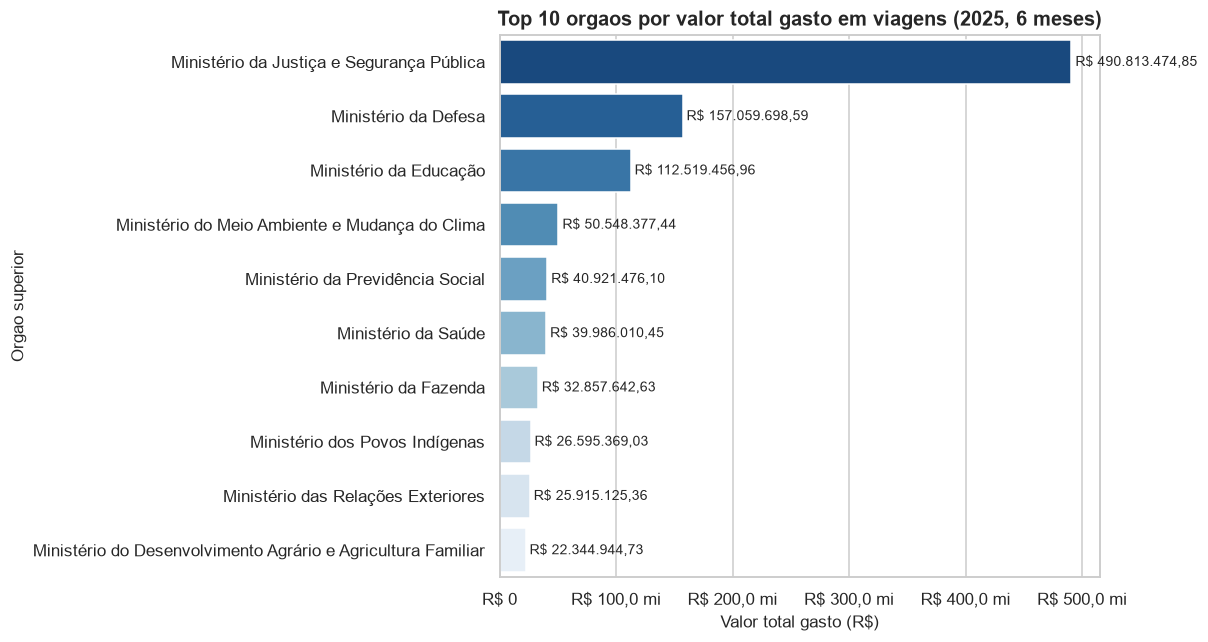

In [6]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=df_p1, y="nome_orgao_superior", x="valor_total_gasto",
    hue="nome_orgao_superior", palette="Blues_r", legend=False, ax=ax,
)
ax.set_title("Top 10 orgaos por valor total gasto em viagens (2025, 6 meses)")
ax.set_xlabel("Valor total gasto (R$)")
ax.set_ylabel("Orgao superior")
ax.xaxis.set_major_formatter(FuncFormatter(fmt_moeda))
for i, valor in enumerate(df_p1["valor_total_gasto"]):
    ax.text(valor, i, f" {formatar_moeda(valor)}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

### Pergunta 2 — Qual o valor médio das viagens por destino?

In [7]:
sql_p2 = """
SELECT
    destino_principal,
    qtd_viagens,
    valor_medio_viagem,
    valor_total_gasto
FROM gold_gastos_por_destino
WHERE qtd_viagens >= 50
ORDER BY valor_medio_viagem DESC
LIMIT 10
"""
df_p2 = consultar_df(sql_p2)
df_p2

,destino_principal,qtd_viagens,valor_medio_viagem,valor_total_gasto
0,Jacareacanga/PA,105,"42.743,59","4.488.076,61"
1,Tucumã/PA,118,"31.297,42","3.693.095,17"
2,Bonn/Alemanha,77,"29.794,03","2.294.140,45"
3,Itaituba/PA,222,"26.569,61","5.898.452,87"
4,Tóquio/Japão,135,"25.727,65","3.473.232,68"
5,Genebra/Suíça,256,"25.638,17","6.563.371,05"
6,Xangai/China,54,"25.417,05","1.372.520,55"
7,Pequim/China,176,"25.158,52","4.427.898,71"
8,Guaíra/PR,118,"25.075,26","2.958.880,78"
9,Montreal/Canadá,75,"24.063,93","1.804.794,47"


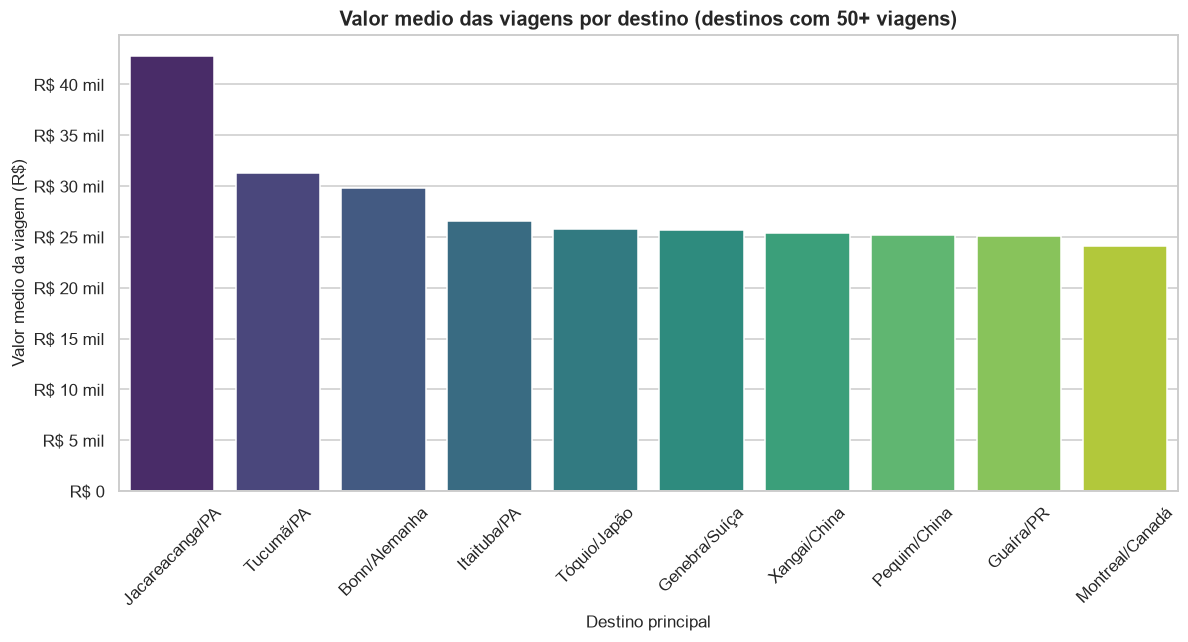

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=df_p2, x="destino_principal", y="valor_medio_viagem",
    hue="destino_principal", palette="viridis", legend=False, ax=ax,
)
ax.set_title("Valor medio das viagens por destino (destinos com 50+ viagens)")
ax.set_xlabel("Destino principal")
ax.set_ylabel("Valor medio da viagem (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(fmt_moeda))
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Pergunta 3 — Quais foram as viagens mais caras, considerando valor_total e duracao_dias?

**Observação:** viagens com duração de 364 dias (01/01 a 31/12) correspondem a
servidores em exercício fora da sede ou viagens continuadas, não a deslocamentos
únicos. O valor_total acumulado reflete o período completo.


In [9]:
sql_p3 = """
SELECT
    id_viagem,
    nome_orgao_superior,
    nome_viajante,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagem
ORDER BY valor_total DESC
LIMIT 15
"""
df_p3 = consultar_df(sql_p3)
df_p3

,id_viagem,nome_orgao_superior,nome_viajante,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020914280,Ministério da Defesa,RENATO RODRIGUES DE AGUIAR FREIRE,2025-05-16,2025-06-03,18,"261.287,40"
1,0000000000020690771,Ministério de Minas e Energia,PIETRO ADAMO SAMPAIO MENDES,2025-01-08,2025-01-21,13,"245.852,80"
2,0000000000020557147,Ministério da Justiça e Segurança Pública,JULYANA DOS SANTOS COELHO,2025-01-01,2025-12-31,364,"216.729,36"
3,0000000000020733847,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-09,2025-10-31,295,"213.987,50"
4,0000000000020649880,Ministério da Justiça e Segurança Pública,BRUNO REZENDE CABRAL,2025-01-01,2025-12-31,364,"207.220,14"
5,0000000000020961121,Ministério das Relações Exteriores,BERNARD JORG LEOPOLD DE GARCIA KLINGL,2025-05-03,2025-05-12,9,"206.166,51"
6,0000000000020678030,Ministério da Justiça e Segurança Pública,JORGE LUIZ FELIX REBOUCAS,2025-01-01,2025-10-24,296,"193.658,60"
7,0000000000020829543,Ministério da Saúde,ISABELLA MANJUD MALUF,2025-04-21,2025-05-30,39,"190.227,82"
8,0000000000020829850,Ministério da Saúde,MARCUS ANDRE MORAES VERDAN,2025-04-21,2025-05-30,39,"190.211,07"
9,0000000000020648908,Ministério da Justiça e Segurança Pública,PAULO PEDRO DA SILVA,2025-01-01,2025-10-24,296,"183.068,50"


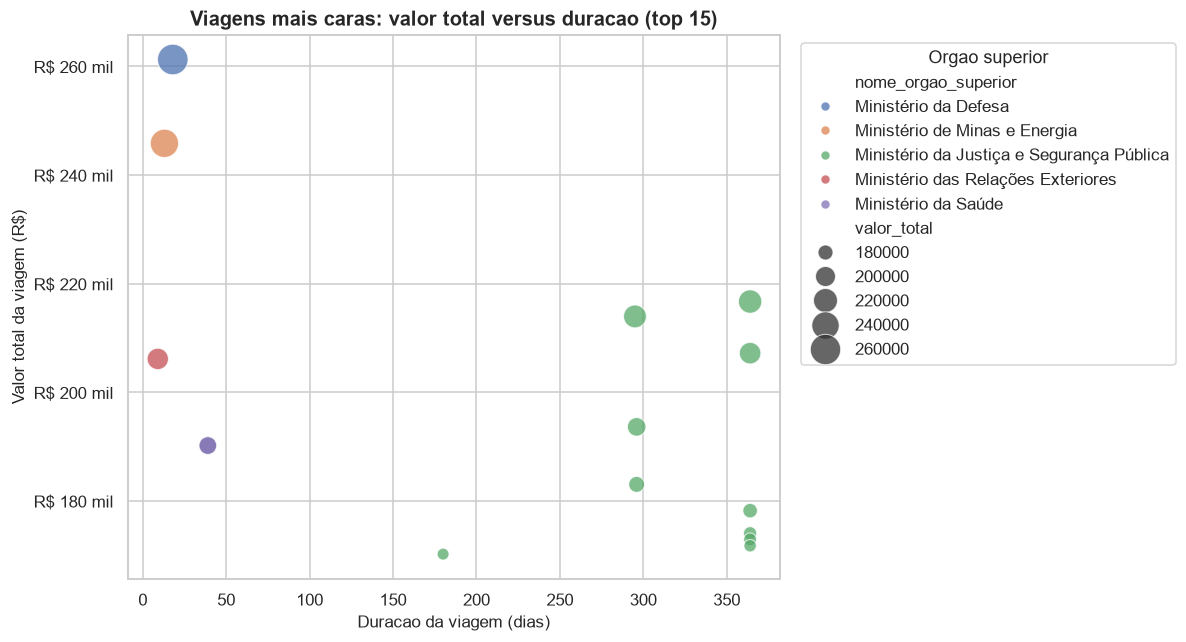

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(
    data=df_p3, x="duracao_dias", y="valor_total",
    size="valor_total", sizes=(60, 400), hue="nome_orgao_superior",
    alpha=0.75, ax=ax,
)
ax.set_title("Viagens mais caras: valor total versus duracao (top 15)")
ax.set_xlabel("Duracao da viagem (dias)")
ax.set_ylabel("Valor total da viagem (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(fmt_moeda))
ax.legend(title="Orgao superior", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Pergunta 4 — Qual o valor médio pago por tipo de pagamento?

In [11]:
sql_p4 = """
SELECT
    tipo_pagamento,
    COUNT(*)                    AS qtd_pagamentos,
    ROUND(AVG(valor), 2)        AS valor_medio,
    SUM(valor)                  AS valor_total
FROM silver_pagamento
GROUP BY tipo_pagamento
ORDER BY valor_medio DESC
"""
df_p4 = consultar_df(sql_p4)
df_p4

,tipo_pagamento,qtd_pagamentos,valor_medio,valor_total
0,PASSAGEM,186006,"1.856,79","345.374.617,87"
1,DIÁRIAS,365945,"1.794,34","656.629.482,75"
2,Serviço correlato: seguro,4882,"447,72","2.185.792,32"
3,RESTITUIÇÃO,11570,"245,69","2.842.678,82"


### Pergunta 5 — Quantos trechos de viagem foram registrados por meio de transporte?

Inválido | 26659 | 3,49


In [12]:
sql_p5 = """
SELECT
    meio_transporte,
    COUNT(*)                                            AS qtd_trechos,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS percentual
FROM silver_trecho
GROUP BY meio_transporte
ORDER BY qtd_trechos DESC
"""
df_p5 = consultar_df(sql_p5)
df_p5

,meio_transporte,qtd_trechos,percentual
0,Veículo Oficial,386424,"50,62"
1,Aéreo,232666,"30,48"
2,Rodoviário,64970,"8,51"
3,Veículo Próprio,42846,"5,61"
4,Inválido,26659,"3,49"
5,Fluvial,8429,"1,10"
6,Ferroviário,874,"0,11"
7,Marítimo,481,"0,06"


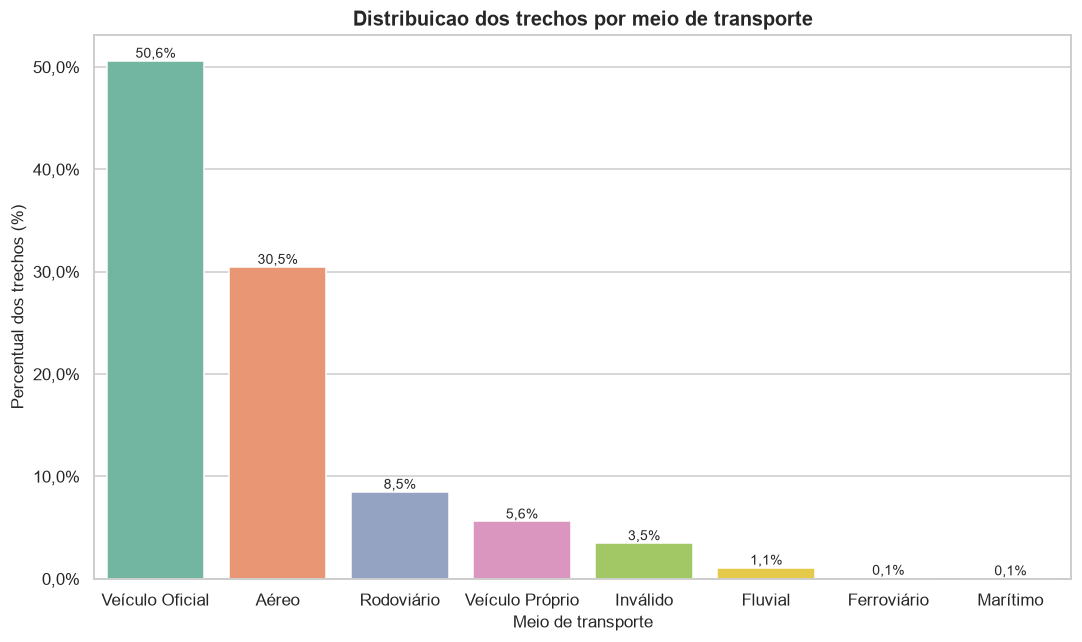

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=df_p5, x="meio_transporte", y="percentual",
    hue="meio_transporte", palette="Set2", legend=False, ax=ax,
)
ax.set_title("Distribuicao dos trechos por meio de transporte")
ax.set_xlabel("Meio de transporte")
ax.set_ylabel("Percentual dos trechos (%)")
ax.yaxis.set_major_formatter(FuncFormatter(fmt_percentual))
for i, valor in enumerate(df_p5["percentual"]):
    ax.text(i, valor, f"{valor:.1f}%".replace(".", ","), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### Pergunta 6 — Quantos trechos cada viagem tem, em média, e qual o recorde?


**Nota:** 290.259 das 341.860 viagens (84,9%) possuem trecho registrado.
A média considera apenas essas viagens.

In [14]:
sql_p6 = """
WITH trechos_por_viagem AS (
    SELECT id_viagem, COUNT(*) AS qtd_trechos
    FROM silver_trecho
    GROUP BY id_viagem
)
SELECT
    ROUND(AVG(qtd_trechos), 2)  AS media_trechos,
    MAX(qtd_trechos)            AS recorde_trechos,
    MIN(qtd_trechos)            AS minimo_trechos,
    COUNT(*)                    AS viagens_com_trecho
FROM trechos_por_viagem
"""
df_p6 = consultar_df(sql_p6)
df_p6

,media_trechos,recorde_trechos,minimo_trechos,viagens_com_trecho
0,"2,63",68,1,290259


In [15]:
sql_p6b = """
SELECT id_viagem, COUNT(*) AS qtd_trechos
FROM silver_trecho
GROUP BY id_viagem
ORDER BY qtd_trechos DESC
LIMIT 5
"""
df_p6b = consultar_df(sql_p6b)
df_p6b

,id_viagem,qtd_trechos
0,0000000000020681145,68
1,0000000000020681203,66
2,0000000000020667807,66
3,0000000000020677976,64
4,0000000000020671088,64


### Pergunta 7 — Como os gastos se distribuem entre os órgãos ao longo do período?

In [16]:
sql_p7 = """
SELECT
    DATE_TRUNC('month', data_inicio)::date  AS mes,
    nome_orgao_superior,
    SUM(valor_total)                        AS valor_total
FROM silver_viagem
GROUP BY mes, nome_orgao_superior
ORDER BY mes, valor_total DESC
"""
df_p7 = consultar_df(sql_p7)
df_p7.head(20)

,mes,nome_orgao_superior,valor_total
0,2025-01-01,Ministério da Justiça e Segurança Pública,"235.393.238,14"
1,2025-01-01,Ministério da Defesa,"11.561.908,55"
2,2025-01-01,Ministério da Educação,"6.570.129,55"
3,2025-01-01,Ministério da Previdência Social,"4.202.798,41"
4,2025-01-01,Ministério dos Povos Indígenas,"4.111.654,93"
5,2025-01-01,Ministério do Meio Ambiente e Mudança do Clima,"3.326.716,44"
6,2025-01-01,Ministério da Saúde,"2.940.687,66"
7,2025-01-01,Ministério da Fazenda,"2.447.734,74"
8,2025-01-01,Ministério do Planejamento e Orçamento,"2.036.652,06"
9,2025-01-01,Presidência da República,"1.807.578,95"


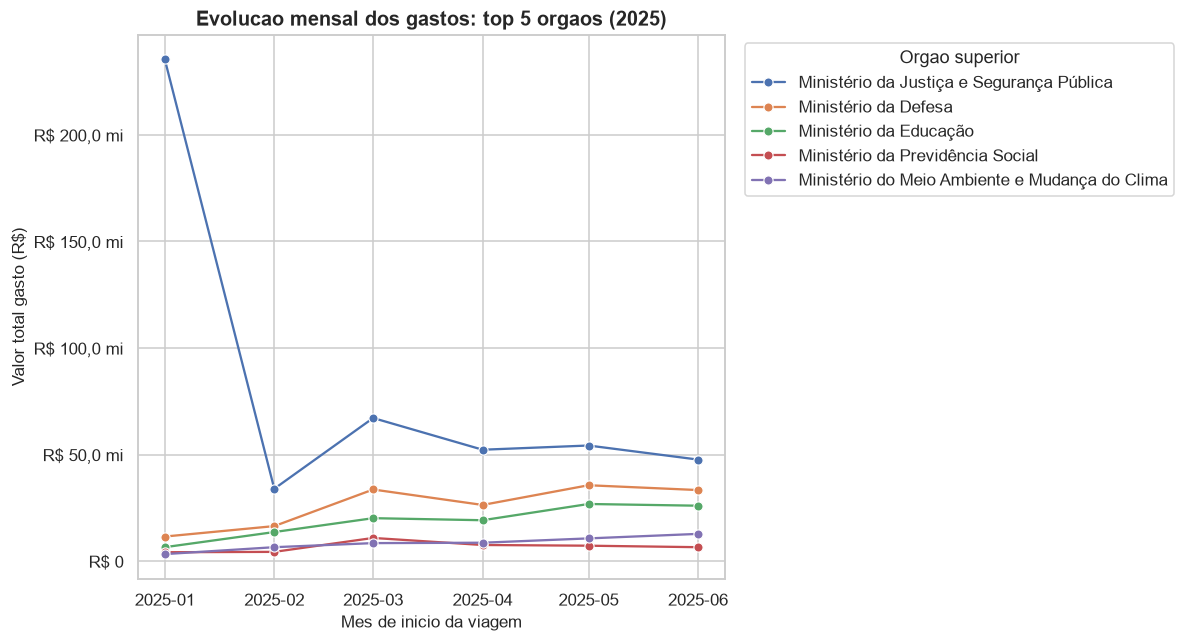

In [17]:
top5_orgaos = (
    df_p7.groupby("nome_orgao_superior")["valor_total"]
    .sum().nlargest(5).index.tolist()
)
df_p7_top = df_p7[df_p7["nome_orgao_superior"].isin(top5_orgaos)]

fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(
    data=df_p7_top, x="mes", y="valor_total",
    hue="nome_orgao_superior", marker="o", ax=ax,
)
ax.set_title("Evolucao mensal dos gastos: top 5 orgaos (2025)")
ax.set_xlabel("Mes de inicio da viagem")
ax.set_ylabel("Valor total gasto (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(fmt_moeda))
ax.legend(title="Orgao superior", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 2. Conclusões

In [18]:
resumo = consultar_df("""
SELECT
    (SELECT COUNT(*) FROM silver_viagem)         AS viagens,
    (SELECT COUNT(*) FROM silver_pagamento)      AS pagamentos,
    (SELECT COUNT(*) FROM silver_passagem)       AS passagens,
    (SELECT COUNT(*) FROM silver_trecho)         AS trechos,
    (SELECT SUM(valor_total) FROM silver_viagem) AS gasto_total
""")
resumo

,viagens,pagamentos,passagens,trechos,gasto_total
0,341860,568403,100075,763349,"1.200.760.089,85"


In [19]:
conexao.close()
print("Conexao encerrada")

Conexao encerrada
